# Decision Tree: Hotel Booking Cancellations

Uses **Clea's cleaned data** (`df1` from the `clea` branch, same as Inez's logistic regression), so every model is trained on the same rows and features. Section 1b adds only the encoding the tree needs.

Random seed 888 everywhere, relative CSV path, runs top-to-bottom on a fresh kernel.
Running all cells also saves the 4 charts, `results_table.csv` and `leakage_check.csv` to this folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

SEED = 888
np.random.seed(SEED)

df_raw = pd.read_csv("HotelBookings.csv")
print(df_raw.shape)
print("Cancellation rate:", round(df_raw["is_canceled"].mean(), 3))

(69710, 30)
Cancellation rate: 0.273


## 1. Data preparation

**1a. Clea's cleaning**, copied from the `clea` branch (`Team Project.ipynb`, the variable creation, drop, `adr` and leakage cells) in the same order, wrapped in a function. Result: 69,646 rows, the same `df1` as Clea and Inez.

Summary of what it does:
- removes 64 rows: 61 bookings with zero `adr`, nights booked, no adults and not complementary; 1 `Undefined` market segment; 2 `Undefined` distribution channels
- caps `adr` at 1,000 (the 5,400 entry error)
- groups countries (top 10 + OTHER) and agents (any with 1%+ of bookings + Other + None)
- creates `has_children`, `has_history`, `prior_cancel_rate`, `has_agent`, `has_company`, `was_waitlisted`, `log_lead_time`, `has_changes`, `adr_zero`, `arrival_dow`
- drops `required_car_parking_spaces` / `has_parking` and `room_changed` as leakage (both are only known once the guest arrives)

Two small additions so the same function works on the Part 3 test file: the country and agent groups are learned from the training data and reused, and rows are only removed from training data (every test booking needs a prediction).

**1b. Extra steps for the tree only:**

| Step | Why |
|---|---|
| `log_lead_time` dropped, `lead_time` kept | a tree splits the same way on either, keeping both only splits the importance between them |
| `arrival_date_month` turned into a month number | keeps the order of the months; one column instead of 12 |
| Text columns one-hot encoded | sklearn trees only take numbers |

In [2]:
def clea_clean(df, ref=None):
    """Clea's cleaning (clea branch), same steps and order.
    ref=None : training data. Learns the agent and country groups and removes the 64 rows.
    ref=dict : new data (Part 3). Reuses the training groups and keeps every row.
    Returns df1 (Clea's cleaned data), leaky (the two dropped leakage columns, same rows), ref."""
    fit = ref is None
    if fit:
        ref = {}
    df = df.copy()

    ## CREATING NEW VARIABLES
    df["arrival_date"] = pd.to_datetime(
        df["arrival_date_year"].astype(str) + "-" + df["arrival_date_month"] + "-"
        + df["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")
    df["booking_date"] = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
    df["arrival_dow"] = df["arrival_date"].dt.dayofweek
    df["has_children"] = ((df["children"].fillna(0) + df["babies"]) > 0).astype(int)
    df["room_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)

    prior_total = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
    df["has_history"] = (prior_total > 0).astype(int)
    df["has_prior_cancel"] = (df["previous_cancellations"] > 0).astype(int)
    df["prior_cancel_rate"] = (df["previous_cancellations"] / prior_total.replace(0, np.nan)).fillna(0)

    df["has_agent"] = df["agent"].notna().astype(int)
    if fit:   # agents with at least 1% of all bookings
        ref["top_agents"] = df["agent"].value_counts(normalize=True, dropna=False).loc[lambda s: s >= 0.01].index
    df["top_agent"] = np.where(df["agent"].isna(), "None",
                               np.where(df["agent"].isin(ref["top_agents"]),
                                        df["agent"].fillna(0).astype(int).astype(str), "Other"))
    df["has_company"] = df["company"].notna().astype(int)
    df["has_parking"] = (df["required_car_parking_spaces"] > 0).astype(int)
    df["was_waitlisted"] = (df["days_in_waiting_list"] > 0).astype(int)
    df["log_lead_time"] = np.log1p(df["lead_time"])

    ## CONVERSIONS
    df["meal"] = df["meal"].replace("Undefined", "SC")
    df["country"] = df["country"].replace("CN", "CHN")
    if fit:   # top 10 countries + OTHER
        ref["top_countries"] = df["country"].value_counts().nlargest(10).index
    df["country_grp"] = df["country"].where(df["country"].isin(ref["top_countries"]), "OTHER")
    df["adr"] = df["adr"].clip(lower=0, upper=1000)

    if fit:   # 1 'Undefined' market segment and 2 'Undefined' distribution channels
        df = df[df["market_segment"] != "Undefined"]
        df = df[df["distribution_channel"] != "Undefined"]

    df1 = df.drop(columns=["agent", "company", "required_car_parking_spaces", "days_in_waiting_list",
                           "has_prior_cancel", "country", "reserved_room_type", "assigned_room_type",
                           "booking_date", "arrival_date", "arrival_date_week_number",
                           "children", "babies", "previous_cancellations"])

    df1["has_changes"] = (df1["booking_changes"] > 0).astype(int)

    # remove the 61 bookings: adr 0, nights booked, not complementary, no adults
    total_nights = df1["stays_in_weekend_nights"] + df1["stays_in_week_nights"]
    zero = df1["adr"] == 0
    if fit:
        df1 = df1[~(zero & (total_nights > 0) & (df1["market_segment"] != "Complementary") & (df1["adults"] == 0))]

    df1["adr_zero"] = (df1["adr"] == 0).astype(int)

    # leakage: parking and room change are only known once the guest arrives
    leaky = df1[["room_changed", "has_parking"]].copy()
    df1 = df1.drop(columns=["room_changed", "has_parking"])
    return df1, leaky, ref


MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                       "August", "September", "October", "November", "December"], start=1)}

def prepare_data(df, add_back=(), ref=None):
    """Clea's cleaning, then the encoding the tree needs.
    add_back: leakage columns to put back in (only for the leakage check in Section 8).
    ref=None for training data; pass the training ref for the Part 3 test file.
    Returns X, y, ref."""
    fit = ref is None
    d, leaky, ref = clea_clean(df, ref)
    for col in add_back:
        d[col] = leaky[col]

    d = d.drop(columns=["log_lead_time"])
    d["arrival_month"] = d.pop("arrival_date_month").map(MONTHS)

    cat_cols = d.select_dtypes(include=["object", "string", "category"]).columns.tolist()
    d = pd.get_dummies(d, columns=cat_cols, dtype=int)

    y = d["is_canceled"] if "is_canceled" in d else None
    X = d.drop(columns=["is_canceled"], errors="ignore")
    if fit and not add_back:
        ref["columns"] = X.columns
    elif not fit:
        # categories missing from new data become 0 columns, unseen ones are dropped
        X = X.reindex(columns=ref["columns"], fill_value=0)
    return X, y, ref

X, y, ref = prepare_data(df_raw)
print("Rows after cleaning:", len(X), "| Features after encoding:", X.shape[1])
print("Any missing left:", X.isna().any().any())

Rows after cleaning: 69646 | Features after encoding: 69
Any missing left: False


## 2. Train / validation split

Stratified so both sets keep the ~27% cancellation rate. **All models in the group should use this same split** so the comparison is fair.

In [3]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "cancel rate", round(y_train.mean(), 3))
print("Val:  ", X_val.shape, "cancel rate", round(y_val.mean(), 3))

Train: (55716, 69) cancel rate 0.273
Val:   (13930, 69) cancel rate 0.273


## 3. Evaluation helper

Accuracy alone is misleading here: predicting "no cancellation" for everyone already scores ~73%.
So we report precision, recall, F1 and ROC-AUC too. **The group should agree on one main metric.**

In [4]:
results = []

def evaluate(name, model):
    pred_tr = model.predict(X_train)
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, 1]
    row = {
        "model": name,
        "train_f1": f1_score(y_train, pred_tr),
        "val_accuracy": accuracy_score(y_val, pred),
        "val_precision": precision_score(y_val, pred),
        "val_recall": recall_score(y_val, pred),
        "val_f1": f1_score(y_val, pred),
        "val_roc_auc": roc_auc_score(y_val, proba),
    }
    results.append(row)
    return pd.Series(row)

baseline_acc = 1 - y_val.mean()
print(f"Naive baseline (always predict 'not cancelled') accuracy: {baseline_acc:.3f}")

Naive baseline (always predict 'not cancelled') accuracy: 0.727


## 4. Unrestricted tree: shows overfitting

A tree with no limits memorises the training data. The gap between train and validation F1 is the evidence for tuning.

In [5]:
tree_full = DecisionTreeClassifier(random_state=SEED)
tree_full.fit(X_train, y_train)
print("Depth:", tree_full.get_depth(), "| Leaves:", tree_full.get_n_leaves())
evaluate("Unrestricted tree", tree_full)

Depth: 49 | Leaves: 8460


model            Unrestricted tree
train_f1                  0.995573
val_accuracy              0.780546
val_precision             0.597532
val_recall                0.598947
val_f1                    0.598239
val_roc_auc               0.724251
dtype: object

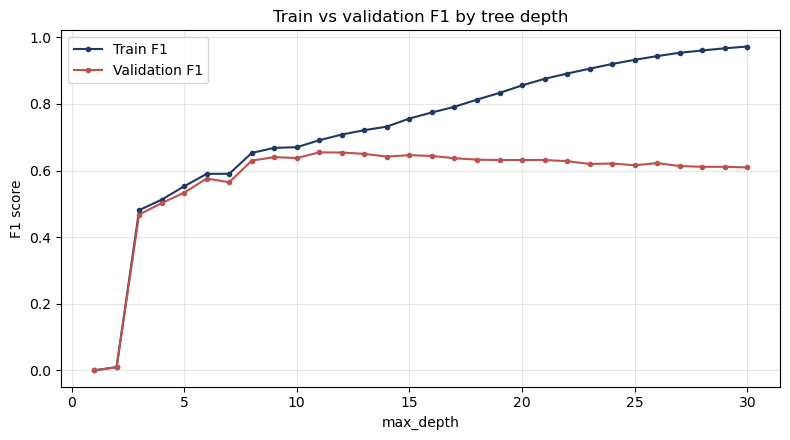

In [6]:
depths = range(1, 31)
train_scores, val_scores = [], []
for dep in depths:
    m = DecisionTreeClassifier(max_depth=dep, random_state=SEED).fit(X_train, y_train)
    train_scores.append(f1_score(y_train, m.predict(X_train)))
    val_scores.append(f1_score(y_val, m.predict(X_val)))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, train_scores, marker="o", ms=3, label="Train F1", color="#1f3864")
ax.plot(depths, val_scores, marker="o", ms=3, label="Validation F1", color="#c0504d")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 score")
ax.set_title("Train vs validation F1 by tree depth")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig("1_depth_chart.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Tuning with cross-validation

Grid search over depth, minimum leaf size, split criterion and class weighting, with 5-fold stratified CV on the training set only.
Scoring on F1 as a placeholder, change `SCORING` if the group picks another metric.

In [7]:
SCORING = "f1"

param_grid = {
    "max_depth": [4, 6, 8, 10, 12, 15, None],
    "min_samples_leaf": [1, 5, 20, 50, 100],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid,
                    scoring=SCORING, cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print(f"Best CV {SCORING}: {grid.best_score_:.3f}")
best_tree = grid.best_estimator_
print("Leaves:", best_tree.get_n_leaves(), "| Depth:", best_tree.get_depth())
evaluate("Tuned tree", best_tree)

Best params: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 50}
Best CV f1: 0.670
Leaves: 504 | Depth: 15


model            Tuned tree
train_f1           0.690276
val_accuracy       0.772936
val_precision      0.556342
val_recall         0.827632
val_f1             0.665397
val_roc_auc        0.872196
dtype: object

## 6. Results comparison

In [8]:
results_df = pd.DataFrame(results).set_index("model").round(3)
results_df.to_csv("results_table.csv")
results_df

,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
model,,,,,,
Unrestricted tree,0.996,0.781,0.598,0.599,0.598,0.724
Tuned tree,0.690,0.773,0.556,0.828,0.665,0.872


               precision    recall  f1-score   support

Not cancelled       0.92      0.75      0.83     10130
    Cancelled       0.56      0.83      0.67      3800

     accuracy                           0.77     13930
    macro avg       0.74      0.79      0.75     13930
 weighted avg       0.82      0.77      0.78     13930



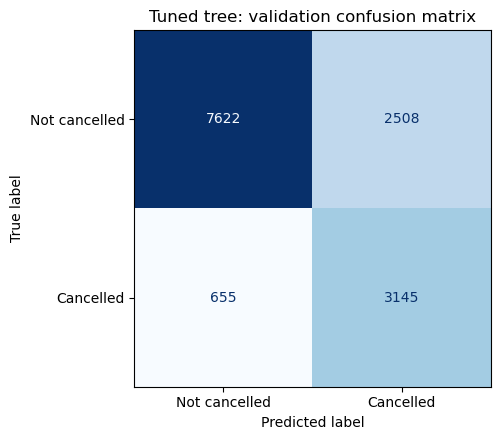

In [9]:
pred = best_tree.predict(X_val)
print(classification_report(y_val, pred, target_names=["Not cancelled", "Cancelled"]))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                       display_labels=["Not cancelled", "Cancelled"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Tuned tree: validation confusion matrix")
plt.tight_layout()
fig.savefig("2_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Interpretation

This is the tree's main strength for the hotel: the rules can be read in plain English.

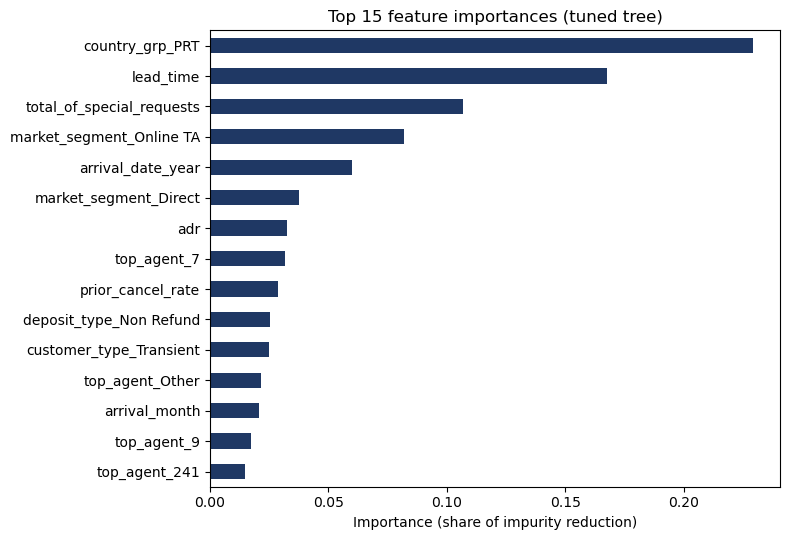

country_grp_PRT              0.229
lead_time                    0.167
total_of_special_requests    0.107
market_segment_Online TA     0.082
arrival_date_year            0.060
market_segment_Direct        0.038
adr                          0.033
top_agent_7                  0.032
prior_cancel_rate            0.029
deposit_type_Non Refund      0.025
customer_type_Transient      0.025
top_agent_Other              0.022
arrival_month                0.021
top_agent_9                  0.017
top_agent_241                0.015
dtype: float64

In [10]:
imp = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5.5))
imp[::-1].plot.barh(ax=ax, color="#1f3864")
ax.set_title("Top 15 feature importances (tuned tree)")
ax.set_xlabel("Importance (share of impurity reduction)")
plt.tight_layout()
fig.savefig("3_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
imp.round(3)

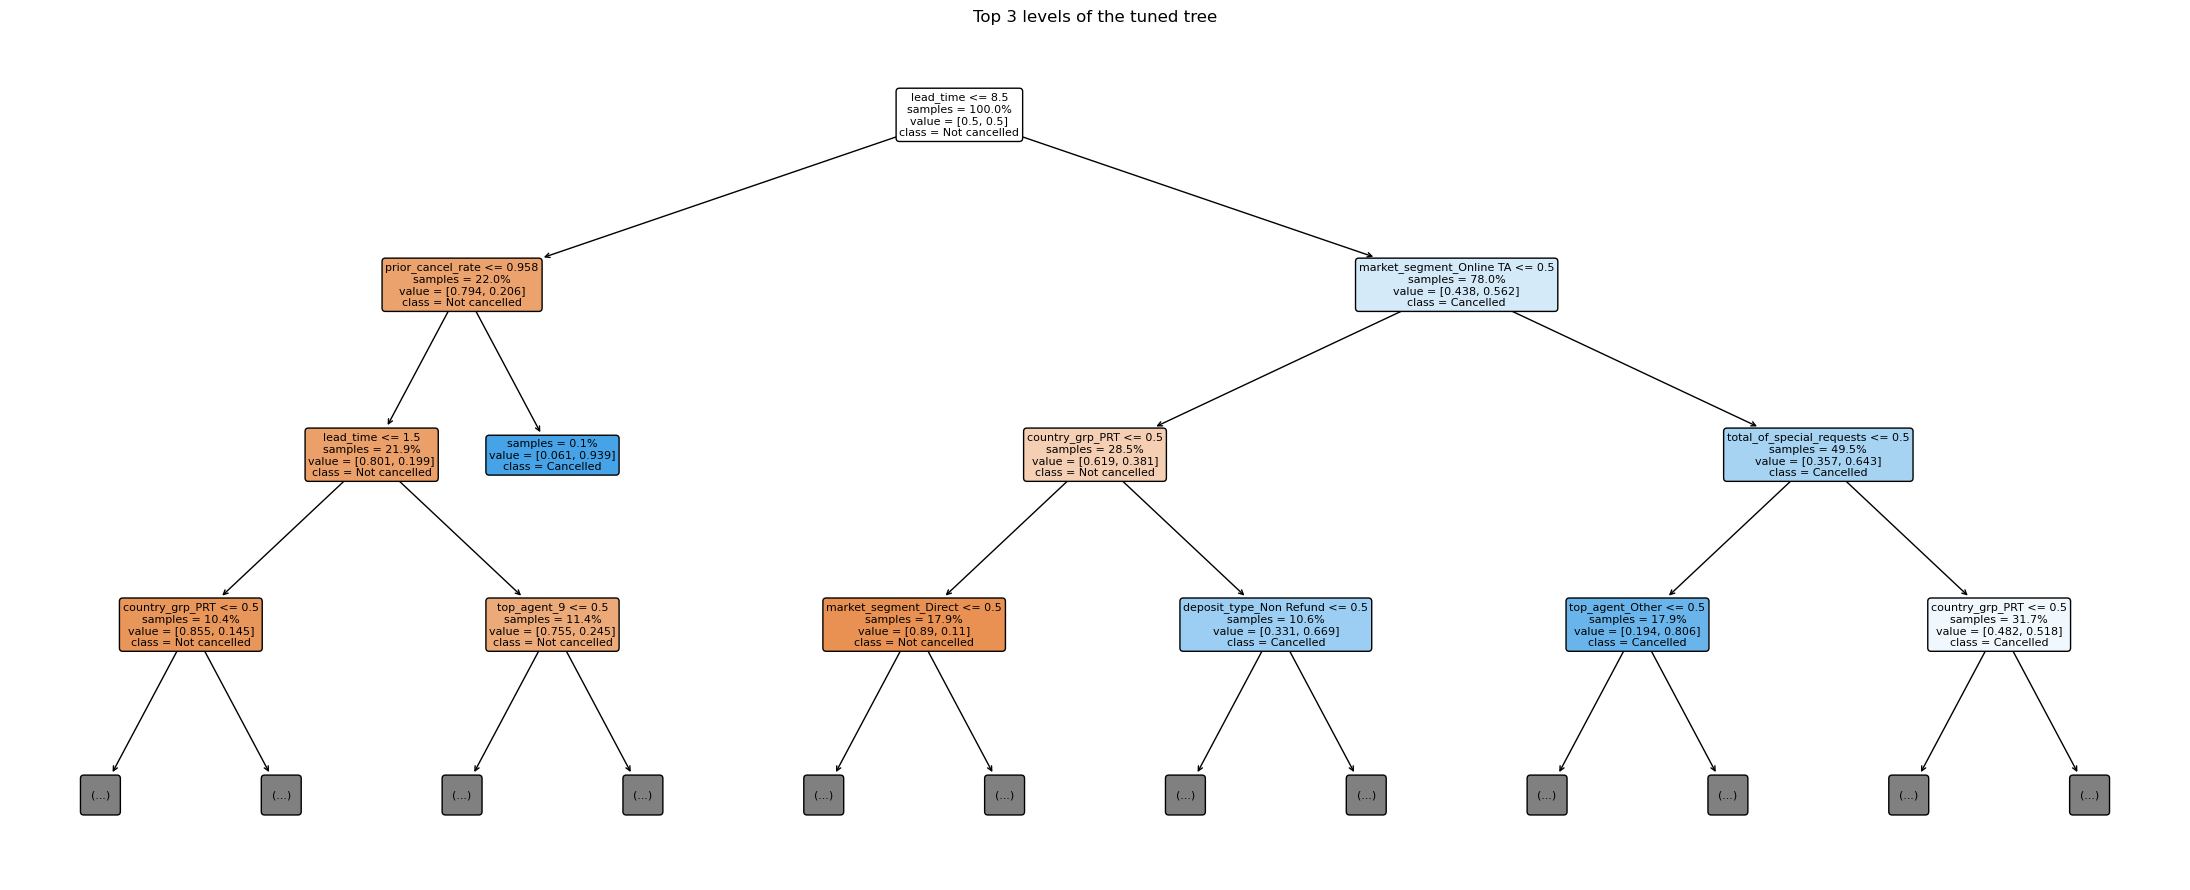

In [11]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(best_tree, max_depth=3, feature_names=X.columns,
          class_names=["Not cancelled", "Cancelled"], filled=True, rounded=True,
          fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title("Top 3 levels of the tuned tree")
plt.tight_layout()
fig.savefig("4_tree_top3_levels.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Leakage check

Same split, same tuned settings as above; only the features change. Clea's cleaning drops two variables as leakage. This shows what putting each one back would do:
- **Baseline**: the tuned tree above (Clea's data)
- **+ room_changed**: whether the guest got a different room from the one booked
- **+ has_parking**: whether the guest needed a parking space

Both are only known once the guest arrives, so a booking that cancelled can almost never have them. Any score gain from them is not real, which is why they stay out.

In [12]:
best_params = best_tree.get_params()

variants = {
    "Baseline (tuned tree)": (),
    "+ room_changed": ("room_changed",),
    "+ has_parking": ("has_parking",),
}

rows = []
for name, cols in variants.items():
    Xv_all, _, _ = prepare_data(df_raw, add_back=cols)          # same rows and order as X
    Xtr, Xv = Xv_all.loc[X_train.index], Xv_all.loc[X_val.index]
    m = DecisionTreeClassifier(**best_params).fit(Xtr, y_train)
    pred, proba = m.predict(Xv), m.predict_proba(Xv)[:, 1]
    rows.append({"variant": name,
                 "val_accuracy": accuracy_score(y_val, pred),
                 "val_precision": precision_score(y_val, pred),
                 "val_recall": recall_score(y_val, pred),
                 "val_f1": f1_score(y_val, pred),
                 "val_roc_auc": roc_auc_score(y_val, proba)})

leakage_df = pd.DataFrame(rows).set_index("variant").round(3)
leakage_df.to_csv("leakage_check.csv")
leakage_df

,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
variant,,,,,
Baseline (tuned tree),0.773,0.556,0.828,0.665,0.872
+ room_changed,0.783,0.570,0.839,0.679,0.880
+ has_parking,0.786,0.572,0.854,0.685,0.888


In [13]:
# Cancellation rates behind the two leakage variables
_, leaky, _ = clea_clean(df_raw)
print(pd.crosstab(leaky["room_changed"], y, normalize="index").round(3))
print(pd.crosstab(leaky["has_parking"], y, normalize="index").round(3))

is_canceled       0      1
room_changed              
0             0.687  0.313
1             0.955  0.045
is_canceled      0      1
has_parking              
0            0.702  0.298
1            1.000  0.000


## 9. Notes for the group

- **Data:** built on Clea's cleaned data, so results are comparable with the other models. Same 80/20 split (stratified, seed 888).
- **Leakage check:** Section 8 shows how much `room_changed` and `has_parking` would inflate the scores if they were left in.
- **Part 3 (held-out test):** reuse the values learned from the training data, so the test file is prepared exactly the same way:
  ```python
  df_test = pd.read_csv("HotelBookings_Test.csv")
  X_test, _, _ = prepare_data(df_test, ref=ref)   # ref = from training, NOT refit on test
  best_tree.predict(X_test)
  ```
  No retraining. `prepare_data` keeps every test row and already lines up the columns.